# LicenseWise — Phase 2 Results
ENSF 621 · Software Licensing Explainability with LLMs

Contents
1. Setup
2. What changed since Phase 1
3. Verifier: entailment threshold (ML-5)
4. Verifier: fine-tuning DeBERTa (ML-6) — configurations, confusion, template memorisation
5. Stage 1: prompt v2 and model comparison (ML-2/3/4)
6. Software engineering: database, tests, CI/CD
7. Strengths, weaknesses, future work

Figures are saved to `docs/figures/` with a `p2_` prefix. Every number is read from files in
`data/processed/`; re-run the notebook after new results land.

## 1. Setup

In [1]:
import json, sys, statistics as st
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
DATA = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Validated reference palette (light mode): categorical slots in fixed order.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, SURFACE, INK, INK2 = "#b4b2ac", "#fcfcfb", "#0b0b0b", "#52514e"
SEQ = mcolors.LinearSegmentedColormap.from_list("seq_blue", ["#eef4fc", BLUE, "#0f3d75"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": "#d8d6cf", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def hbar(ax, labels, values, colors, fmt="{:,}", total=None):
    y = range(len(labels))[::-1]
    ax.barh(list(y), values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(list(y), labels)
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values):
        txt = fmt.format(v) + (f"  ({v / total:.0%})" if total else "")
        ax.text(v, yi, "  " + txt, va="center", color=INK2, fontsize=10)
    ax.set_xlim(0, max(values) * 1.28)

from run_nli import human_labels
NLI = DATA / "nli"
SCEN = DATA / "scenarios"
LABELS = ["entailment", "neutral", "contradiction"]
load_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text().splitlines() if l]

## 2. What changed since Phase 1

| Area | Phase 1 | Phase 2 | Why |
|---|---|---|---|
| Verifier decision | argmax over NLI classes | threshold on P(entailment) tuned (ML-5), then replaced by fine-tuning | base model missed many true claims (entailment recall 0.69) |
| Verifier model | DeBERTa-v3-large (MNLI/FEVER/ANLI/LING/WANLI), off the shelf | top 4 of 24 layers fine-tuned on our 729 clause–claim pairs | license language is far from NLI training data |
| Verifier data | 729 pairs, used only for testing | same pairs, 5-fold grouped cross-validation (by license / by claim template), human label where available | no new labelling budget; grouping prevents leakage |
| Stage 1 prompt | catalogue = title + description | catalogue + choosealicense labels; "check every requirement, then rank" (v2) | most wrong picks broke a stated constraint the labels answer directly |
| Stage 1 model | gpt-oss-120b | gpt-oss-120b vs gpt-oss-20b compared | cost / latency trade-off |
| Backend | none (UI used saved examples) | FastAPI, async jobs, SQLite history | the UI runs the real pipeline |
| Engineering | manual checks | 27 pytest tests (LLM + NLI mocked), ruff, GitHub Actions on `development` and `main` | CI/CD requirement, regression safety |

## 3. Verifier: entailment threshold (ML-5)

A claim is *verified* if P(entailment) ≥ t. t is chosen on the 583 pairs **without** human labels
(best macro-F1 while entailment precision ≥ 0.90), then reported on the 146 human-labelled pairs.

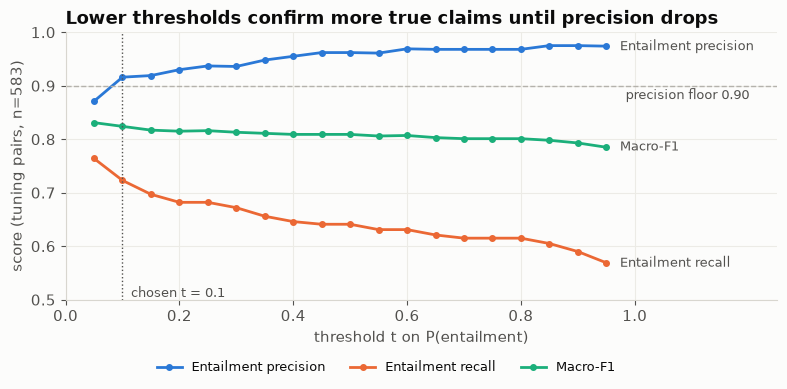

,accuracy,macro_F1,P(ent),R(ent)
rule,,,,
argmax (Phase 1),0.815,0.816,0.944,0.694
t = 0.1,0.829,0.830,0.925,0.755


In [2]:
thr = json.loads((NLI / "threshold_predictions_deberta-v3-large-nli.json").read_text())
curve = pd.DataFrame(thr["curve_on_tuning_pairs"])
t_best = thr["chosen_t"]

fig, ax = plt.subplots(figsize=(8, 4.2))
for col, name, color in [("entailment_precision", "Entailment precision", BLUE),
                         ("entailment_recall", "Entailment recall", ORANGE),
                         ("macro_f1", "Macro-F1", AQUA)]:
    ax.plot(curve["t"], curve[col], color=color, lw=2, marker="o", ms=4, label=name)
    ax.text(0.96, curve[col].iloc[-1], "  " + name, va="center", color=INK2, fontsize=9)
ax.axhline(thr["min_precision"], color=GRAY, lw=1, ls="--")
ax.text(0.97, thr["min_precision"] - 0.025, "  precision floor 0.90", color=INK2, fontsize=9)
ax.axvline(t_best, color=INK2, lw=1, ls=":")
ax.text(t_best + 0.015, 0.505, f"chosen t = {t_best}", color=INK2, fontsize=9)
ax.set(xlabel="threshold t on P(entailment)", ylabel="score (tuning pairs, n=583)", ylim=(0.5, 1.0), xlim=(0, 1.25))
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title("Lower thresholds confirm more true claims until precision drops")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.32), ncol=3, frameon=False, fontsize=9)
save(fig, "p2_01_threshold_curve")

rows = []
for name, m in [("argmax (Phase 1)", thr["human_test"]["argmax"]), (f"t = {t_best}", thr["human_test"]["tuned"])]:
    e = m["per_class"]["entailment"]
    rows.append({"rule": name, "accuracy": m["accuracy"], "macro_F1": m["macro_f1"], "P(ent)": e["precision"], "R(ent)": e["recall"]})
pd.DataFrame(rows).set_index("rule")

## 4. Verifier: fine-tuning DeBERTa (ML-6)

Only the top K encoder layers + classifier are trained; the frozen lower layers' outputs are cached once
(fits a 16 GB laptop). 5-fold cross-validation, out-of-fold predictions:

- **license-grouped**: a license's pairs are never in train and test together (main setting);
- **label-grouped**: all pairs of a claim *template* (e.g. "commercial use allowed") are held out together —
  a stress test for memorising template wording.

Hyperparameters: lr 2e-5, 3 epochs, batch 8, AdamW (wd 0.01), 10% warm-up, seed 13. K=8 did not fit in memory.

In [3]:
base_all = json.loads((NLI / "nli_results.json").read_text())
ft = json.loads((NLI / "finetune" / "results.json").read_text())
configs = [
    ("Base, argmax (Phase 1)", base_all["deberta-v3-large-nli"]["human"]),
    (f"Base, t = {t_best} (ML-5)", thr["human_test"]["tuned"]),
    ("Fine-tuned K=2, license-held-out", ft["license_k2_lr2e-05_e3_b8_s13"]["human_test"]),
    ("Fine-tuned K=4, license-held-out", ft["license_k4_lr2e-05_e3_b8_s13"]["human_test"]),
    ("Fine-tuned K=4, template-held-out", ft["label_k4_lr2e-05_e3_b8_s13"]["human_test"]),
]
table = pd.DataFrame([{"configuration": n, "accuracy": m["accuracy"], "macro_F1": m["macro_f1"],
                       "P(ent)": m["per_class"]["entailment"]["precision"],
                       "R(ent)": m["per_class"]["entailment"]["recall"],
                       "minutes": None} for n, m in configs]).set_index("configuration")
for name, key in [("Fine-tuned K=2, license-held-out", "license_k2"), ("Fine-tuned K=4, license-held-out", "license_k4"),
                  ("Fine-tuned K=4, template-held-out", "label_k4")]:
    table.loc[name, "minutes"] = ft[f"{key}_lr2e-05_e3_b8_s13"].get("minutes")
table

,accuracy,macro_F1,P(ent),R(ent),minutes
configuration,,,,,
"Base, argmax (Phase 1)",0.815,0.816,0.944,0.694,None
"Base, t = 0.1 (ML-5)",0.829,0.830,0.925,0.755,None
"Fine-tuned K=2, license-held-out",0.897,0.897,0.936,0.898,33.5
"Fine-tuned K=4, license-held-out",0.925,0.925,0.978,0.918,185.0
"Fine-tuned K=4, template-held-out",0.911,0.911,0.933,0.857,149.3


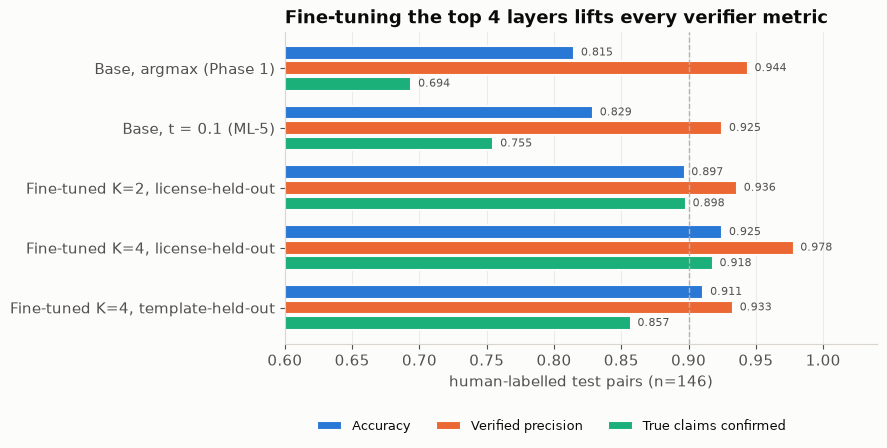

In [4]:
metrics = [("accuracy", "Accuracy", BLUE), ("P(ent)", "Verified precision", ORANGE), ("R(ent)", "True claims confirmed", AQUA)]
fig, ax = plt.subplots(figsize=(9, 4.8))
n = len(table); h = 0.26
for j, (col, name, color) in enumerate(metrics):
    ys = [i * 1.0 + (1 - j) * h for i in range(n)][::-1]
    ax.barh(ys, table[col], height=h - 0.03, color=color, edgecolor=SURFACE, linewidth=1.5, label=name)
    for y, v in zip(ys, table[col]):
        ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8, color=INK2)
ax.set_yticks(list(range(n))[::-1], table.index)
ax.axvline(0.90, color=GRAY, lw=1, ls="--")
ax.set(xlim=(0.6, 1.04), xlabel="human-labelled test pairs (n=146)")
ax.grid(axis="y", visible=False)
ax.set_title("Fine-tuning the top 4 layers lifts every verifier metric")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.32), ncol=3, frameon=False, fontsize=9)
save(fig, "p2_02_verifier_configs")

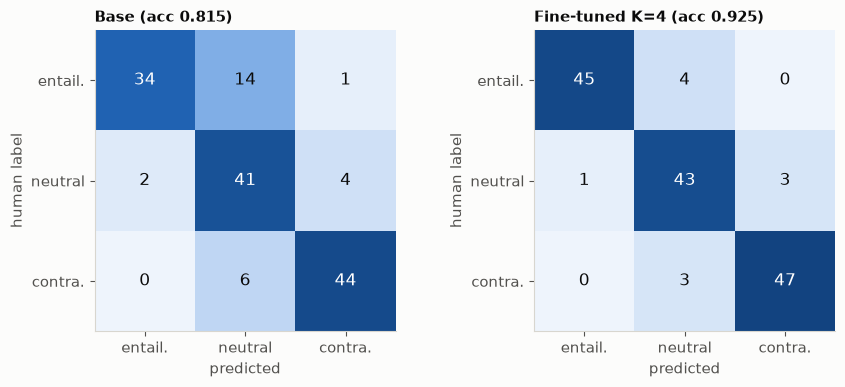

In [5]:
def conf_matrix(ax, m, title):
    M = [[m["confusion"][g][p] for p in LABELS] for g in LABELS]
    ax.imshow(M, cmap=SEQ, vmin=0, vmax=50)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, M[i][j], ha="center", va="center", fontsize=12,
                    color="white" if M[i][j] > 28 else INK)
    ax.set_xticks(range(3), ["entail.", "neutral", "contra."]); ax.set_yticks(range(3), ["entail.", "neutral", "contra."])
    ax.set_xlabel("predicted"); ax.set_ylabel("human label"); ax.grid(False)
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
conf_matrix(axes[0], base_all["deberta-v3-large-nli"]["human"], f"Base (acc {base_all['deberta-v3-large-nli']['human']['accuracy']:.3f})")
conf_matrix(axes[1], ft["license_k4_lr2e-05_e3_b8_s13"]["human_test"], f"Fine-tuned K=4 (acc {ft['license_k4_lr2e-05_e3_b8_s13']['human_test']['accuracy']:.3f})")
save(fig, "p2_03_confusion_base_vs_finetuned")

**Template memorisation.** Entailment recall per claim template, on all 729 pairs (human label where
available, otherwise the automatic label). If the license-held-out score is far above the
template-held-out score for a label, the gain there comes from having seen that wording in training.

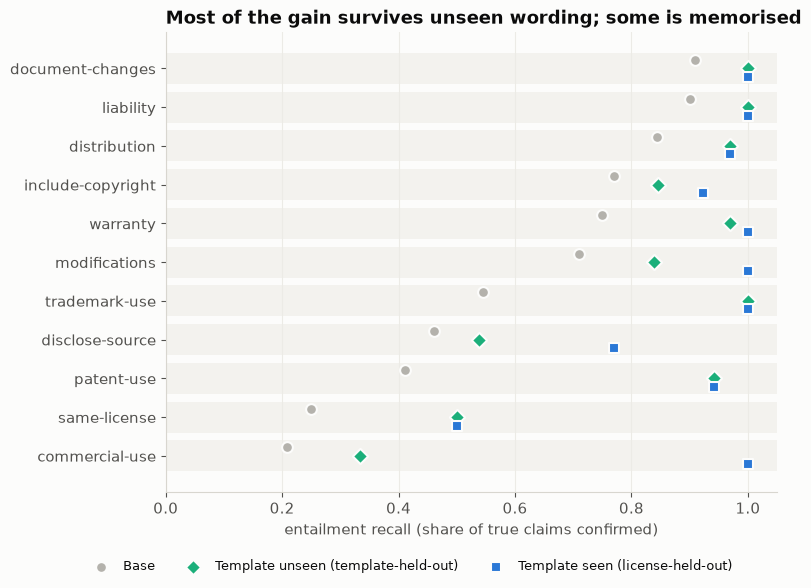

,Base,Template seen (license-held-out),Template unseen (template-held-out)
commercial-use,0.21,1.00,0.33
same-license,0.25,0.50,0.50
patent-use,0.41,0.94,0.94
disclose-source,0.46,0.77,0.54
trademark-use,0.55,1.00,1.00
modifications,0.71,1.00,0.84
warranty,0.75,1.00,0.97
include-copyright,0.77,0.92,0.85
distribution,0.84,0.97,0.97
liability,0.90,1.00,1.00


In [6]:
pairs = {p["pair_id"]: p for p in load_jsonl(NLI / "pairs.jsonl")}
human = human_labels()
gold = {i: human.get(i, p["nli_label"]) for i, p in pairs.items()}
preds = {
    "Base": {p["pair_id"]: max(p["probs"], key=p["probs"].get) for p in load_jsonl(NLI / "predictions_deberta-v3-large-nli.jsonl")},
    "Template seen (license-held-out)": {p["pair_id"]: p["predicted"] for p in load_jsonl(NLI / "finetune" / "oof_license_k4_lr2e-05_e3_b8_s13.jsonl")},
    "Template unseen (template-held-out)": {p["pair_id"]: p["predicted"] for p in load_jsonl(NLI / "finetune" / "oof_label_k4_lr2e-05_e3_b8_s13.jsonl")},
}
rec = {}
for name, pr in preds.items():
    by = {}
    for i, g in gold.items():
        if g == "entailment":
            by.setdefault(pairs[i]["label"], []).append(pr[i] == "entailment")
    rec[name] = {k: sum(v) / len(v) for k, v in by.items() if len(v) >= 8}
recall = pd.DataFrame(rec).sort_values("Base")
fig, ax = plt.subplots(figsize=(8, 0.42 * len(recall) + 1.4))
for (name, color, marker, dy) in [("Base", GRAY, "o", 0.22), ("Template unseen (template-held-out)", AQUA, "D", 0), ("Template seen (license-held-out)", BLUE, "s", -0.22)]:
    ax.scatter(recall[name], [y + dy for y in range(len(recall))], color=color, s=60, marker=marker, label=name, zorder=3,
               edgecolor=SURFACE, linewidth=1.5)
for y in range(len(recall)):
    ax.axhspan(y - 0.4, y + 0.4, color="#f3f2ee", zorder=0, lw=0)
ax.set_yticks(range(len(recall)), recall.index)
ax.set(xlim=(0, 1.05), xlabel="entailment recall (share of true claims confirmed)")
ax.grid(axis="y", visible=False)
ax.set_title("Most of the gain survives unseen wording; some is memorised")
ax.legend(loc="lower center", bbox_to_anchor=(0.4, -0.38 if len(recall) < 8 else -0.2), ncol=3, frameon=False, fontsize=9)
save(fig, "p2_04_template_memorisation")
recall.round(2)

**Real Stage 2 claims (preview, not human-labelled).** The 37 claims with a found quote from saved pipeline
runs, re-verified with both models (no LLM calls):

| | verified | unverified | contradicted |
|---|---|---|---|
| Base DeBERTa | 24 | 11 | 2 |
| Fine-tuned K=4 | 32 | 4 | 1 |

All 8 changed claims read as correct against their clauses (author's reading).
The deployed verifier is the K=4 model retrained on all 729 pairs (~4 min).

## 5. Stage 1: prompt v2 and model comparison (ML-2/3/4)

All configurations run on the **same descriptions** as the Phase 1 baseline (paired comparison).
Only one new prompt was tried, designed from the Phase 1 error analysis before any new results, so no
separate tuning split is needed. Metrics: Hit@1 (top pick satisfies every constraint), Hit@3, Precision@3.

In [7]:
runs = {
    "v1 · gpt-oss-120b (Phase 1)": SCEN / "stage1_results.jsonl",
    "v2 · gpt-oss-120b": SCEN / "stage1_results_v2_gpt-oss-120b.jsonl",
    "v1 · gpt-oss-20b": SCEN / "stage1_results_v1_gpt-oss-20b.jsonl",
}
res = {k: {r["desc_id"]: r for r in load_jsonl(p)} for k, p in runs.items() if Path(p).exists()}
common = sorted(set.intersection(*(set(v) for v in res.values())))
print(f"paired descriptions (done in every configuration): {len(common)} of {len(res['v1 · gpt-oss-120b (Phase 1)'])}")
for k, v in res.items():
    print(f"  {k}: {len(v)} done")
s1 = pd.DataFrame({k: {m: sum(v[i][m] for i in common) / len(common) for m in ("hit@1", "hit@3", "precision@3")}
                   for k, v in res.items()}).T.round(3)
s1

paired descriptions (done in every configuration): 104 of 104
  v1 · gpt-oss-120b (Phase 1): 104 done
  v2 · gpt-oss-120b: 104 done
  v1 · gpt-oss-20b: 104 done


,hit@1,hit@3,precision@3
v1 · gpt-oss-120b (Phase 1),0.558,0.740,0.548
v2 · gpt-oss-120b,0.885,0.942,0.849
v1 · gpt-oss-20b,0.548,0.692,0.519


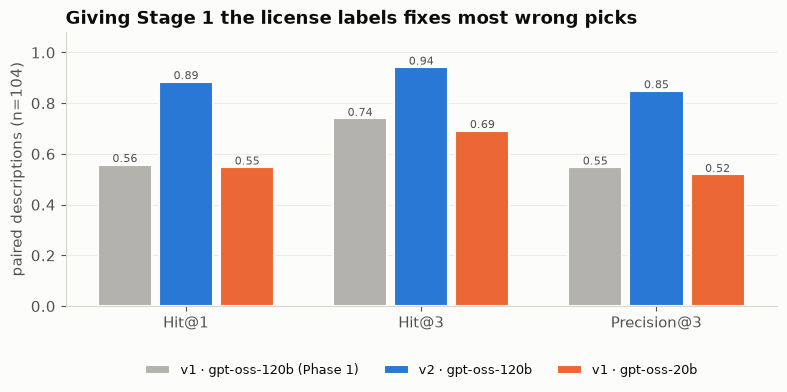

In [8]:
colors = [GRAY, BLUE, ORANGE]
fig, ax = plt.subplots(figsize=(8, 4.2))
w = 0.26
for j, (cfg, color) in enumerate(zip(s1.index, colors)):
    xs = [i + (j - 1) * w for i in range(3)]
    ax.bar(xs, s1.loc[cfg], width=w - 0.03, color=color, edgecolor=SURFACE, linewidth=1.5, label=cfg)
    for x, v in zip(xs, s1.loc[cfg]):
        ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(range(3), ["Hit@1", "Hit@3", "Precision@3"])
ax.set(ylim=(0, 1.08), ylabel=f"paired descriptions (n={len(common)})")
ax.grid(axis="x", visible=False)
ax.set_title("Giving Stage 1 the license labels fixes most wrong picks")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False, fontsize=9)
save(fig, "p2_05_stage1_configs")

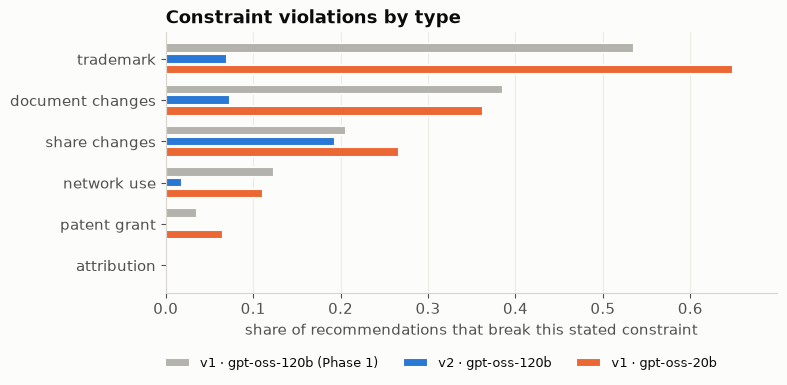

,v1 · gpt-oss-120b (Phase 1),v2 · gpt-oss-120b,v1 · gpt-oss-20b
attribution,0.000,0.000,0.000
patent_grant,0.036,0.000,0.065
network_use,0.123,0.019,0.111
share_changes,0.207,0.193,0.267
document_changes,0.385,0.074,0.363
trademark,0.535,0.070,0.649


In [9]:
profiles = {p["profile_id"]: p for p in load_jsonl(SCEN / "profiles.jsonl")}
viol = {}
for k, v in res.items():
    tot, bad = Counter(), Counter()
    for i in common:
        r = v[i]
        for rec in r["recommended"]:
            for dim in profiles[r["profile_id"]]["constraints"]:
                tot[dim] += 1
            for dim in rec["violates"]:
                bad[dim] += 1
    viol[k] = {d: bad[d] / tot[d] for d in tot}
viol = pd.DataFrame(viol).sort_values("v1 · gpt-oss-120b (Phase 1)")
fig, ax = plt.subplots(figsize=(8, 4.2))
h = 0.26
for j, (cfg, color) in enumerate(zip(viol.columns, colors)):
    ys = [i + (1 - j) * h for i in range(len(viol))]
    ax.barh(ys, viol[cfg], height=h - 0.03, color=color, edgecolor=SURFACE, linewidth=1.5, label=cfg)
ax.set_yticks(range(len(viol)), [d.replace("_", " ") for d in viol.index])
ax.set(xlabel="share of recommendations that break this stated constraint", xlim=(0, max(0.6, viol.values.max() + 0.05)))
ax.grid(axis="y", visible=False)
ax.set_title("Constraint violations by type")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.34), ncol=3, frameon=False, fontsize=9)
save(fig, "p2_06_stage1_violations")
viol.round(3)

**Cost.** v2 adds ~1.5k input tokens per request (~6k tokens per description vs ~4.2k). On Groq's free tier
(200k tokens/day, 8k tokens/minute per model) that is ~33 descriptions/day, and a few v2 requests were rejected
as too large for the per-minute limit (see section 7).

## 6. Software engineering

| Item | What | Where |
|---|---|---|
| Backend | FastAPI: `POST /api/recommendations` → 202 + job id; UI polls `GET /api/recommendations/{id}`; one worker thread; identical inputs reuse results | `licensewise/api.py` |
| Database | SQLite `data/runs/licensewise.db`, table `jobs(id, input_key, status, created_at, data JSON)`; Phase 1 JSON jobs imported once | `licensewise/api.py` |
| Tests | 27 pytest tests, LLM and NLI mocked (no key, no model download, < 1 s) | `tests/` |
| Lint | ruff (Python), oxlint (UI) | `pyproject.toml`, `ui/package.json` |
| CI/CD | GitHub Actions on push/PR to `development` and `main`: backend (ruff + pytest) and UI (lint, type-check, build) | `.github/workflows/ci.yml` |
| Branching | `development` = integration, `main` = stable/demo; changes reach `main` by PR with passing checks | GitHub |
| Reproducibility | pinned `requirements*.txt`; experiment log with reasons | `PROJECT_LOG.txt` |

In [10]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

27 passed in 0.36s


## 7. Strengths, weaknesses, future work

**Strengths**
- Verifier: accuracy 0.815 → 0.925 (license-held-out), verified precision 0.978, above the 0.90 requirement;
  still 0.911 / 0.933 when the claim wording is unseen.
- Stage 1: labels in the prompt cut constraint violations sharply at no model cost.
- Cheap: partial fine-tuning runs on a laptop (4 min for the final model) thanks to cached frozen layers.

**Weaknesses**
- Part of the verifier gain is template memorisation (e.g. commercial-use recall 0.21 → 1.00 seen vs 0.33 unseen).
- Unseen wording produced 1 contradiction marked verified (base model: 0).
- Real Stage 2 claims are only previewed, not human-labelled.
- v2 prompt is ~40% more tokens; on the free tier some requests exceed the per-minute limit.
- Stage 1 test descriptions are LLM-generated from constraint profiles, not written by real developers.

**Future work**
- Paraphrase claim templates for fine-tuning; human-label real Stage 2 claims (RQ3).
- Compact v2 catalogue (labels only) to stay under per-request limits.
- Self-consistency (3 samples + vote) for Stage 1; claims phrased in the license's own words (ML-7).
- User study with developers; more licenses (non-OSI, custom).